# Final stage, Experiment 2: model comparison with random search

**Problem statement:** *Can we predict how severe a major power outage will become, using historical outage data and recent storm information available when the outage starts?*

**Question of this experiment:** which model works best for each target, storm rule and scenario, and how much does tuning help?

**Design (decided before running):**

| | |
|---|---|
| Setups | **2a main:** train before 2022, test 2022–2023 (2024 excluded, see Experiment 1). **2b source-consistent:** OE-417 reports only, train Jul 2016–2020, test 2021–2023. |
| Runs | **strict storm rule (R2, operational)**, base model (no infrastructure data), scenarios **A (pre-event)** and **B (with cause)**, 3 targets. The four storm rules were compared in the progress stage and performed alike, so the final experiments use the operational rule. |
| Models | regression: Ridge, Lasso, Random Forest, XGBoost; classification (is_severe): Logistic regression, Random Forest, XGBoost |
| Search | `RandomizedSearchCV`, 25 settings per model (fewer when the space is smaller), 4 time-based inner folds on the training years, recency weights |
| Selection | the best model per combination is chosen by **cross-validation score only**; test scores are shown for every model for transparency |
| is_severe | threshold chosen for F1 on the training years' cross-validation predictions |

The data pipeline (sections 0–6) is the same as in the progress-stage notebook. Results are saved after every combination (`results/exp2_all_models.csv`), so the run can be resumed.

-----

In [1]:
import io
import os
import re
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (ExtraTreesClassifier, ExtraTreesRegressor,
                              RandomForestClassifier, RandomForestRegressor)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             brier_score_loss, f1_score, mean_absolute_error, precision_score,
                             r2_score, recall_score, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, mean_squared_error

## 1. Configuration


In [2]:
# project folder = the first parent folder that contains Data/
ROOT = os.getcwd()
while not os.path.isdir(os.path.join(ROOT, "Data")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)
DATA_DIR = os.path.join(ROOT, "Data")
RAW_EXT = os.path.join(DATA_DIR, "ext_raw")  # ONI, Census, BEA downloads
PUDL = os.path.join(DATA_DIR, "pudl_raw")  # EIA-861 / FERC Form 1 parquet files
OUT_DIR = os.path.join(os.getcwd(), "results")  # CSV / PNG outputs, next to this notebook
os.makedirs(OUT_DIR, exist_ok=True)

SEED = 42
TEST_START = pd.Timestamp("2022-01-01")  # used only for the summary printout in section 6
OUTAGE_FILE = "outage_extended.xlsx"  # Purdue 2000-2016 + DOE OE-417 2016-2024
NWS_FILE = os.path.join(DATA_DIR, "nws_raw", "nws_events.parquet")
NWS_START = pd.Timestamp(
    "2006-01-01"
)  # all watch / warning types archived from 12 Nov 2005
FORM_2024 = pd.Timestamp("2024-01-01")  # OE-417 form revision
REGIME_YEAR = 2011  # reporting changed around 2011

# targets
EXCLUDE_ZEROS = (
    True  # 0 customers / 0 minutes = no interruption -> not a severity target
)

# storm matching
LOOKBACK_HOURS = 24  # storm active within 24 h before the outage start
LOOKBACK = np.timedelta64(24, "h")
BUFFER = np.timedelta64(1, "h")  # strict rule: storm began >= 1 h before the start

# history features
SMOOTHING = 5.0  # shrink small-sample means toward the prior

# models
HALF_LIFE_YEARS = 4.0  # recency weight: 4 years older counts half
COST_RATIOS = [1, 3, 5]  # missed severe outage : false alarm

TASKS = {
    "customers_reg": ("reg", "log_customers"),
    "duration_reg": ("reg", "log_duration"),
    "is_severe": ("bin", None),
}

## 2. Data loading

### Outages

- `outage_extended.xlsx` has 4,279 reports: Purdue (2000 – Jul 2016) plus DOE OE-417 (Jul 2016 – 2024).

In [3]:
def merge_same_event(raw):
    """One row per (start, state): keep the report with the most information."""
    key = ["OUTAGE.START.DATE", "OUTAGE.START.TIME", "U.S._STATE"]
    info = raw["CUSTOMERS.AFFECTED"].notna().astype(int) + raw[
        "OUTAGE.DURATION"
    ].notna().astype(int)
    keep = (
        raw.assign(_info=info)
        .sort_values("_info", ascending=False, kind="mergesort")
        .drop_duplicates(key)
        .index
    )
    out = raw.loc[sorted(keep)].reset_index(drop=True)
    print(f"Merged reports of the same event: {len(raw)} -> {len(out)} rows")
    return out

###  NOAA Storm Events

- One CSV per year, 2000–2024.
- Event types are grouped into families (wind, winter, cold, tropical, tornado, flood, hail, heat, lightning, fire, other).
- Droughts are removed: they last months and are listed once per zone.
- Events are stored per state, sorted by begin time, so matching is fast.

In [4]:
NOAA_COLS = [
    "STATE",
    "BEGIN_DATE_TIME",
    "END_DATE_TIME",
    "EVENT_TYPE",
    "MAGNITUDE",
    "CZ_TYPE",
    "CZ_FIPS",
]


def read_csv_safely(path, **kwargs):
    """Read a NOAA CSV that may contain null bytes or mixed line endings."""
    with open(path, "rb") as fh:
        raw = fh.read().replace(b"\x00", b"")
    text = (
        raw.decode("latin1", errors="replace").replace("\r\n", "\n").replace("\r", "\n")
    )
    return pd.read_csv(io.StringIO(text), **kwargs)


def load_noaa(data_dir=DATA_DIR):
    files = sorted(
        os.path.join(data_dir, f)
        for f in os.listdir(data_dir)
        if re.search(r"StormEvents", f)
    )
    noaa_df = pd.concat(
        [
            read_csv_safely(
                f,
                on_bad_lines="skip",
                low_memory=False,
                dtype=str,
                usecols=lambda c: c in NOAA_COLS,
            )
            for f in files
        ],
        ignore_index=True,
    )
    print(f"NOAA data: {len(noaa_df)} rows from {len(files)} files")
    return noaa_df

In [5]:
EVENT_FAMILY = {
    "Thunderstorm Wind": "wind",
    "High Wind": "wind",
    "Strong Wind": "wind",
    "Marine Thunderstorm Wind": "wind",
    "Marine High Wind": "wind",
    "Marine Strong Wind": "wind",
    "Winter Storm": "winter",
    "Heavy Snow": "winter",
    "Ice Storm": "winter",
    "Blizzard": "winter",
    "Winter Weather": "winter",
    "Lake-Effect Snow": "winter",
    "Sleet": "winter",
    "Freezing Fog": "winter",
    "Frost/Freeze": "cold",
    "Extreme Cold/Wind Chill": "cold",
    "Cold/Wind Chill": "cold",
    "Hurricane (Typhoon)": "tropical",
    "Hurricane": "tropical",
    "Tropical Storm": "tropical",
    "Tropical Depression": "tropical",
    "Storm Surge/Tide": "tropical",
    "Marine Hurricane/Typhoon": "tropical",
    "Marine Tropical Storm": "tropical",
    "Tornado": "tornado",
    "Waterspout": "tornado",
    "Funnel Cloud": "tornado",
    "Flash Flood": "flood",
    "Flood": "flood",
    "Coastal Flood": "flood",
    "Lakeshore Flood": "flood",
    "Heavy Rain": "flood",
    "Hail": "hail",
    "Marine Hail": "hail",
    "Heat": "heat",
    "Excessive Heat": "heat",
    "Lightning": "lightning",
    "Marine Lightning": "lightning",
    "Wildfire": "fire",
}
FAMILIES = [
    "wind",
    "winter",
    "cold",
    "tropical",
    "tornado",
    "flood",
    "hail",
    "heat",
    "lightning",
    "fire",
    "other",
]
ONGOING_FAMILIES = ["wind", "winter", "tropical", "flood"]


def parse_noaa_time(s):
    out = pd.to_datetime(s, format="%d-%b-%y %H:%M:%S", errors="coerce")
    if out.isna().mean() > 0.5:  # other export format
        out = pd.to_datetime(s, errors="coerce")
    if getattr(out.dt, "tz", None) is not None:
        out = out.dt.tz_localize(None)
    return out


def prepare_noaa(noaa_df):
    """Clean NOAA once; return per-state arrays sorted by storm begin time."""
    n = noaa_df[[c for c in NOAA_COLS if c in noaa_df.columns]].copy()
    n["CLEAN_STATE"] = n["STATE"].astype(str).str.upper().str.strip()
    n["BEGIN_DATE_TIME"] = parse_noaa_time(n["BEGIN_DATE_TIME"])
    n["END_DATE_TIME"] = parse_noaa_time(n["END_DATE_TIME"])
    n = n.dropna(subset=["BEGIN_DATE_TIME", "END_DATE_TIME", "CLEAN_STATE"])
    n = n[n["EVENT_TYPE"] != "Drought"].copy()  # months long, per-zone duplicated
    n["MAGNITUDE"] = pd.to_numeric(n["MAGNITUDE"], errors="coerce")
    n["FAMILY"] = n["EVENT_TYPE"].map(EVENT_FAMILY).fillna("other")
    n["ZONE"] = (
        n["CZ_TYPE"].astype(str) + "_" + n["CZ_FIPS"].astype(str)
        if {"CZ_TYPE", "CZ_FIPS"}.issubset(n.columns)
        else "NA"
    )

    by_state = {}
    for state, g in n.sort_values("BEGIN_DATE_TIME").groupby("CLEAN_STATE"):
        by_state[state] = {
            "begin": g["BEGIN_DATE_TIME"].values.astype("datetime64[ns]"),
            "end": g["END_DATE_TIME"].values.astype("datetime64[ns]"),
            "mag": g["MAGNITUDE"].values.astype(float),
            "event": g["EVENT_TYPE"].astype(str).values,
            "family": g["FAMILY"].astype(str).values,
            "zone": g["ZONE"].astype(str).values,
        }
    return by_state

In [6]:
def load_raw():
    raw = pd.read_excel(os.path.join(DATA_DIR, OUTAGE_FILE))
    raw = merge_same_event(raw)
    if "N.STATES.AFFECTED" in raw.columns: 
        raw["N.STATES.AFFECTED"] = raw["N.STATES.AFFECTED"].fillna(1)
    noaa = prepare_noaa(load_noaa(DATA_DIR))
    for a in noaa.values():  # longest storm per state -> overlap search bound
        a["maxdur"] = (a["end"] - a["begin"]).max()
    return raw, noaa

### NWS watches, warnings and advisories (Iowa Environmental Mesonet)

The National Weather Service issues **watches** (A: conditions favour the hazard), **warnings** (W: hazard happening or imminent) and **advisories** (Y: less severe) for storms, floods, winter weather, heat and more. Source: the IEM archive of every VTEC event, downloaded per state and year by `download_nws_warnings.py`.

**Only real-time information is used:**
- `issue`: when the product was issued;
- `init_expire`: the expiry time announced **at issue**. The final expiry, which can be extended later, is not used.

Times are converted from UTC to the state's main time zone (DST-aware; states spanning two zones use the larger one, so up to 1 h off at the edges).

**Features at outage start** (same state):

| Feature | Meaning |
|---|---|
| `nws_warn_active`, `nws_watch_active`, `nws_adv_active` | warnings / watches / advisories in effect at outage start |
| `nws_warn_active_<family>` | warnings in effect, by family (wind, tornado, winter, tropical, flood, heat, cold, fire, other) |
| `nws_warn_24h`, `nws_warn_7d` | warnings issued in the last 24 h / 7 days |
| `nws_hours_since_warning` | hours since the last warning was issued (capped at 168) |

all product types are archived only from 12 Nov 2005, so outages **before 2006 get missing values** (filled by the model's imputer, with a "was missing" indicator).

In [7]:
NWS_FAMILY = {
    "SV": "wind",
    "HW": "wind",
    "WI": "wind",
    "EW": "wind",
    "LW": "wind",
    "GL": "wind",
    "SR": "wind",
    "TO": "tornado",
    "WS": "winter",
    "BZ": "winter",
    "IS": "winter",
    "WW": "winter",
    "LE": "winter",
    "ZR": "winter",
    "SN": "winter",
    "HS": "winter",
    "SQ": "winter",
    "LB": "winter",
    "SB": "winter",
    "HU": "tropical",
    "TR": "tropical",
    "TY": "tropical",
    "SS": "tropical",
    "HI": "tropical",
    "TI": "tropical",
    "FF": "flood",
    "FA": "flood",
    "FL": "flood",
    "CF": "flood",
    "LS": "flood",
    "HY": "flood",
    "EH": "heat",
    "HT": "heat",
    "XH": "heat",
    "EC": "cold",
    "WC": "cold",
    "FZ": "cold",
    "HZ": "cold",
    "FR": "cold",
    "CW": "cold",
    "XC": "cold",
    "FW": "fire",
}
NWS_FAMILIES = [
    "wind",
    "tornado",
    "winter",
    "tropical",
    "flood",
    "heat",
    "cold",
    "fire",
    "other",
]
NWS_NUM = (
    ["nws_warn_active", "nws_watch_active", "nws_adv_active"]
    + [f"nws_warn_active_{f}" for f in NWS_FAMILIES]
    + ["nws_warn_24h", "nws_warn_7d", "nws_hours_since_warning"]
)
STATE_TZ = {
    **{
        s: "America/New_York"
        for s in [
            "CT",
            "DE",
            "DC",
            "FL",
            "GA",
            "IN",
            "KY",
            "ME",
            "MD",
            "MA",
            "MI",
            "NH",
            "NJ",
            "NY",
            "NC",
            "OH",
            "PA",
            "RI",
            "SC",
            "VT",
            "VA",
            "WV",
        ]
    },
    **{
        s: "America/Chicago"
        for s in [
            "AL",
            "AR",
            "IL",
            "IA",
            "KS",
            "LA",
            "MN",
            "MS",
            "MO",
            "NE",
            "ND",
            "OK",
            "SD",
            "TN",
            "TX",
            "WI",
        ]
    },
    **{s: "America/Denver" for s in ["CO", "ID", "MT", "NM", "UT", "WY"]},
    "AZ": "America/Phoenix",
    **{s: "America/Los_Angeles" for s in ["CA", "NV", "OR", "WA"]},
    "AK": "America/Anchorage",
    "HI": "Pacific/Honolulu",
    "PR": "America/Puerto_Rico",
}


def load_nws(path=NWS_FILE):
    """Watches (A), warnings (W), advisories (Y) per state, local time, sorted by issue time."""
    ev = pd.read_parquet(path)
    ev = ev[
        ev["significance"].isin(["W", "A", "Y"]) & ev["state"].isin(STATE_TZ)
    ].copy()
    ev["family"] = ev["phenomena"].map(NWS_FAMILY).fillna("other")
    by_state = {}
    for st, g in ev.groupby("state"):
        tz = STATE_TZ[st]
        issue = (
            pd.to_datetime(g["issue"], utc=True, errors="coerce")
            .dt.tz_convert(tz)
            .dt.tz_localize(None)
        )
        expire = (
            pd.to_datetime(g["init_expire"], utc=True, errors="coerce")
            .dt.tz_convert(tz)
            .dt.tz_localize(None)
        )
        g = g.assign(issue_local=issue, expire_local=expire.fillna(issue)).dropna(
            subset=["issue_local"]
        )
        g = g.sort_values("issue_local")
        by_state[st] = {
            "issue": g["issue_local"].values.astype("datetime64[ns]"),
            "expire": g["expire_local"].values.astype("datetime64[ns]"),
            "sig": g["significance"].values,
            "family": g["family"].values,
        }
    print(
        f"NWS products: {len(ev)} (watches, warnings, advisories) in {len(by_state)} states"
    )
    return by_state


def nws_features(df, nws_by_state):
    """Real-time warning features at each outage start (NaN before NWS_START)."""
    h = np.timedelta64(1, "h")
    rows = []
    for st, t in zip(
        df["postal_code"].values, df["outage_start"].values.astype("datetime64[ns]")
    ):
        a = nws_by_state.get(st)
        if a is None or np.isnat(t) or t < np.datetime64(NWS_START):
            rows.append({c: np.nan for c in NWS_NUM})
            continue
        hi = np.searchsorted(a["issue"], t, side="right")  # issued before the start
        lo30 = np.searchsorted(a["issue"], t - np.timedelta64(30, "D"))
        idx = np.arange(lo30, hi)
        act = idx[a["expire"][idx] > t]  # in effect at the start
        sig, fam = a["sig"][act], a["family"][act]
        warn = idx[a["sig"][idx] == "W"]
        r = {
            "nws_warn_active": int((sig == "W").sum()),
            "nws_watch_active": int((sig == "A").sum()),
            "nws_adv_active": int((sig == "Y").sum()),
        }
        for f in NWS_FAMILIES:
            r[f"nws_warn_active_{f}"] = int(((sig == "W") & (fam == f)).sum())
        r["nws_warn_24h"] = int((a["issue"][warn] >= t - 24 * h).sum())
        r["nws_warn_7d"] = int((a["issue"][warn] >= t - 168 * h).sum())
        r["nws_hours_since_warning"] = (
            float(min((t - a["issue"][warn].max()) / h, 168.0)) if warn.size else 168.0
        )
        rows.append(r)
    return pd.DataFrame(rows, index=df.index)


nws_by_state = load_nws()

NWS products: 1352918 (watches, warnings, advisories) in 52 states


## 3. Storm matching (NOAA → outage)

Each outage is matched to storm events in the **same state**. Four rules are compared:


1. Original(Proposed): The original version only considered storms that **began** within the lookback window. Problem-A long storm that began before the window and was still active at outage start (for example, a flood that began 20 days earlier) was ignored.(the professor's feedback, W2 fix: overlap)
```
filter: 
lo = np.searchsorted(strom_begin >= lookback_window)# left | strom begins after lookback_window 
hi = np.searchsorted(strom_begin <= outage_start)# right | strom begains befor outage(strom after outage is ignored)
rule: (storm_begin <= outage_start) and  (storm_end >= lookback_window)
```

2. Overlap: To fix problem in original mode, a storm now counts if two things are both true:
1. calamity **began before the outage started**, and
2. calamity **had not already ended more than lookback_window (24) hours before the outage**. 

```
*maxdur is the longest storm duration in that state.
filter: 
lo= np.searchsorted(storm_begin >= (lookback_window − maxdur)) # left
hi = np.searchsorted(storm_begin <= outage_start) # right
rule: (storm_begin <= outage_start)
        and (storm_end >= lookback_window)
```

3. Strict: same as overlap, but the storm must have begun at least 1 hour before the outage:
```
filter: 
lo= np.searchsorted(storm_begin >= (lookback_window − maxdur)) #left
hi = np.searchsorted(storm_begin <= outage_start − buffer)#right | must begain 1 before the outage_start
rule:(storm_begin <= outage_start − buffer)
        and (storm_end >= lookback_window)
```
4. Completed: only storms that had fully ended before the outage started: This is the most  cautious mode; it ignores storms still in progress.
```
filter: 
lo = np.searchsorted(storm_begin >= lookback_window − maxdur)# left
hi = np.searchsorted(storm_begin <= outage_start - buffer) #right
rule: (storm_begin <= outage_start − buffer)
        and (lookback_window <= storm_end <= outage_start) #(storm_end >= lookback_window and storm_end <= outage_start)
```

**Features:** counts in the last 24 h and 7 days, number of zones and event types, counts per family, storm still active at start, hours since the last storm, maximum wind and hail of completed storms, and the most common event type. Damage, injury and death columns are never used.

In [8]:
def empty_storm_row(lookback_hours):
    """Feature values for an outage with no matching storm."""
    row = {
        "noaa_storm_count": 0,
        "noaa_count_7d": 0,
        "noaa_n_zones": 0,
        "noaa_n_types": 0,
        "noaa_n_ongoing": 0,
        "noaa_has_ongoing_storm": 0,
        "noaa_has_storm": 0,
        "hours_since_last_storm": float(lookback_hours),
        "noaa_max_wind_kt": np.nan,
        "noaa_max_hail_in": np.nan,
        "noaa_dominant_event_type": "None",
    }
    row.update({f"noaa_cnt_{f}": 0 for f in FAMILIES})
    row.update({f"noaa_ongoing_{f}": 0 for f in ONGOING_FAMILIES})
    return row


def storm_features_for_outage(a, start, lookback_hours):
    """
    PROPOSAL rule (R0): storms in the same state that BEGAN within the look-back window
    (outage start - LOOKBACK_HOURS <= BEGIN <= outage start). Long-running storms that began
    earlier are not counted (feedback W2).  Magnitudes use completed storms only
    (an ongoing storm's recorded peak may come after the outage began).
    """
    row = empty_storm_row(lookback_hours)
    lb = np.timedelta64(int(lookback_hours), "h")

    hi = np.searchsorted(a["begin"], start, side="right")
    row["noaa_count_7d"] = int(
        hi - np.searchsorted(a["begin"], start - np.timedelta64(7, "D"))
    )
    lo = np.searchsorted(
        a["begin"], start - lb
    )  # proposal rule: storm BEGAN within the window
    idx = np.arange(lo, hi)
    idx = idx[a["end"][idx] >= start - lb]
    if idx.size == 0:
        return row

    end, fam, ev = a["end"][idx], a["family"][idx], a["event"][idx]
    mag, zone = a["mag"][idx], a["zone"][idx]
    ongoing = end > start

    row["noaa_storm_count"] = int(idx.size)
    row["noaa_has_storm"] = 1
    row["noaa_n_zones"] = int(np.unique(zone).size)
    row["noaa_n_types"] = int(np.unique(ev).size)
    row["noaa_n_ongoing"] = int(ongoing.sum())
    row["noaa_has_ongoing_storm"] = int(ongoing.any())
    row["hours_since_last_storm"] = (
        0.0 if ongoing.any() else float((start - end.max()) / np.timedelta64(1, "h"))
    )
    for f in FAMILIES:
        row[f"noaa_cnt_{f}"] = int((fam == f).sum())
    for f in ONGOING_FAMILIES:
        row[f"noaa_ongoing_{f}"] = int(((fam == f) & ongoing).any())
    for col, f in [("noaa_max_wind_kt", "wind"), ("noaa_max_hail_in", "hail")]:
        m = mag[~ongoing & (fam == f)]
        m = m[~np.isnan(m)]
        row[col] = float(m.max()) if m.size else np.nan
    values, counts = np.unique(ev, return_counts=True)
    row["noaa_dominant_event_type"] = values[np.argmax(counts)]
    return row

In [9]:
def storm_row(a, t, mode):
    if mode == "original":
        return storm_features_for_outage(a, t, 24)
    row = empty_storm_row(24)
    t_known = t - BUFFER if mode in ("strict", "completed") else t
    hi = np.searchsorted(a["begin"], t_known, side="right")
    row["noaa_count_7d"] = int(
        hi - np.searchsorted(a["begin"], t_known - np.timedelta64(7, "D"))
    )
    lo = np.searchsorted(a["begin"], t - LOOKBACK - a["maxdur"])
    idx = np.arange(lo, hi)
    idx = idx[a["end"][idx] >= t - LOOKBACK]
    if mode == "completed":
        idx = idx[a["end"][idx] <= t]
    if idx.size == 0:
        return row
    end, fam, ev = a["end"][idx], a["family"][idx], a["event"][idx]
    mag, zone = a["mag"][idx], a["zone"][idx]
    ongoing = end > t
    row.update(
        noaa_storm_count=int(idx.size),
        noaa_has_storm=1,
        noaa_n_zones=int(np.unique(zone).size),
        noaa_n_types=int(np.unique(ev).size),
        noaa_n_ongoing=int(ongoing.sum()),
        noaa_has_ongoing_storm=int(ongoing.any()),
        hours_since_last_storm=(
            0.0 if ongoing.any() else float((t - end.max()) / np.timedelta64(1, "h"))
        ),
    )
    for f in FAMILIES:
        row[f"noaa_cnt_{f}"] = int((fam == f).sum())
    for f in ONGOING_FAMILIES:
        row[f"noaa_ongoing_{f}"] = int(((fam == f) & ongoing).any())
    for col, f in [("noaa_max_wind_kt", "wind"), ("noaa_max_hail_in", "hail")]:
        m = mag[~ongoing & (fam == f)]
        m = m[~np.isnan(m)]
        row[col] = float(m.max()) if m.size else np.nan
    values, counts = np.unique(ev, return_counts=True)
    row["noaa_dominant_event_type"] = values[np.argmax(counts)]
    return row


def storm_features(df, noaa, mode):
    rows = []
    for st, t in zip(
        df["clean_state"].values, df["outage_start"].values.astype("datetime64[ns]")
    ):
        a = noaa.get(st)
        rows.append(
            empty_storm_row(24) if a is None or np.isnat(t) else storm_row(a, t, mode)
        )
    return pd.DataFrame(rows, index=df.index)

## 4. Preprocessing

### Feature lists and leakage guard

`LEAKAGE_COLS` lists columns never used in  model inputs

In [10]:
STATIC_NUM = [
    "anomaly_level",
    "res_price",
    "com_price",
    "ind_price",
    "total_price",
    "res_sales",
    "com_sales",
    "ind_sales",
    "total_sales",
    "res_percen",
    "com_percen",
    "ind_percen",
    "res_customers",
    "com_customers",
    "ind_customers",
    "total_customers",
    "res_cust_pct",
    "com_cust_pct",
    "ind_cust_pct",
    "pc_realgsp_state",
    "pc_realgsp_usa",
    "pc_realgsp_rel",
    "pc_realgsp_change",
    "util_realgsp",
    "total_realgsp",
    "util_contri",
    "pi_util_ofusa",
    "population",
    "poppct_urban",
    "poppct_uc",
    "popden_urban",
    "popden_uc",
    "popden_rural",
    "areapct_urban",
    "areapct_uc",
    "pct_land",
    "pct_water_tot",
    "pct_water_inland",
]
SKEWED = [
    "res_sales",
    "com_sales",
    "ind_sales",
    "total_sales",
    "res_customers",
    "com_customers",
    "ind_customers",
    "total_customers",
    "util_realgsp",
    "total_realgsp",
    "population",
    "popden_urban",
    "popden_uc",
    "popden_rural",
]
TIME_NUM = [
    "start_month",
    "start_hour",
    "is_weekend",
    "post_regime",
    "month_sin",
    "month_cos",
    "hour_sin",
    "hour_cos",
]
NOAA_NUM = (
    [
        "noaa_storm_count",
        "noaa_count_7d",
        "noaa_n_zones",
        "noaa_n_types",
        "noaa_n_ongoing",
        "noaa_has_ongoing_storm",
        "noaa_has_storm",
        "hours_since_last_storm",
        "noaa_max_wind_kt",
        "noaa_max_hail_in",
    ]
    + [f"noaa_cnt_{f}" for f in FAMILIES]
    + [f"noaa_ongoing_{f}" for f in ONGOING_FAMILIES]
)
HIST_NUM = [
    "hist_state_n",
    "hist_state_n_365d",
    "hist_state_cust",
    "hist_state_dur",
    "hist_state_zero_rate",
    "hist_global_cust",
    "hist_global_dur",
]
RECENT_HIST = [
    "hist_global_cust_365d",
    "hist_global_dur_365d",
    "hist_state_cust_3y",
    "hist_state_dur_3y",
    "hist_state_n_30d",
    "hist_global_n_365d",
]
STORM_TE = [
    "hist_storm_cust",
    "hist_storm_dur",
    "hist_state_storm_cust",
    "hist_state_storm_dur",
]
CAUSE_TE = [
    "hist_cause_cust",
    "hist_cause_dur",
    "hist_state_cause_cust",
    "hist_state_cause_dur",
]
AREA_NUM = [
    "area_hist_n",
    "area_hist_n_365d",
    "area_hist_log_cust",
    "area_hist_log_dur",
    "area_hist_attack_share",
    "n_states_affected",
]
BASE_CAT = [
    "nerc_region",
    "climate_region",
    "climate_category",
    "clean_state",
    "noaa_dominant_event_type",
]
CAUSE_CAT = ["cause_reported"]
CAUSE_NUM = ["is_named_hurricane"]
GRID_NUM = []  # HIFLD state-level grid features: not used (no effect in v6)

# never allowed as model inputs (targets or post-event information)
LEAKAGE_COLS = [
    "cause_category",
    "cause_category_detail",
    "cust_reported_zero",
    "customers_affected",
    "demand_loss_mw",
    "hurricane_names",
    "log_customers",
    "log_duration",
    "obs",
    "outage_duration",
    "outage_restoration",
    "outage_restoration_date",
    "outage_restoration_time",
    "start_year",
    "year",
]
EXTRA_LEAKAGE = [
    "alert_criteria",
    "area_affected",
    "area_key",
    "event_type_raw",
    "same_start_reports",
    "source",
]
LEAKAGE_COLS, EXTRA_LEAKAGE = set(LEAKAGE_COLS), set(EXTRA_LEAKAGE)

ECON_EIA = [
    "res_price",
    "com_price",
    "ind_price",
    "total_price",
    "res_sales",
    "com_sales",
    "ind_sales",
    "total_sales",
    "res_percen",
    "com_percen",
    "ind_percen",
    "res_customers",
    "com_customers",
    "ind_customers",
    "total_customers",
    "res_cust_pct",
    "com_cust_pct",
    "ind_cust_pct",
]
ECON_BEA = [
    "pc_realgsp_state",
    "pc_realgsp_usa",
    "pc_realgsp_rel",
    "pc_realgsp_change",
    "util_realgsp",
    "total_realgsp",
    "util_contri",
    "pi_util_ofusa",
]

### Targets and time features

- Start and restoration timestamps are built from the date and time columns.
- Customers are normalised per 100,000 state population. Both targets are log-transformed.
- Rows are sorted by start time, because every split is chronological.
- Time features: month, hour, weekend, cyclic month/hour, and a reporting-regime flag (2011).

In [11]:
def combine_date_time(date_col, time_col):
    out = pd.to_datetime(
        date_col.astype(str) + " " + time_col.astype(str), errors="coerce"
    )
    alt = pd.to_datetime(date_col, errors="coerce").dt.normalize() + pd.to_timedelta(
        time_col.astype(str), errors="coerce"
    )
    return out.fillna(alt)


def create_targets(outage_df, exclude_zeros=EXCLUDE_ZEROS):
    """Timestamps + log targets; keep rows with a start time and >= 1 target."""
    df = outage_df.copy()
    df["OUTAGE_START"] = combine_date_time(
        df["OUTAGE.START.DATE"], df["OUTAGE.START.TIME"]
    )
    df["OUTAGE_RESTORATION"] = combine_date_time(
        df["OUTAGE.RESTORATION.DATE"], df["OUTAGE.RESTORATION.TIME"]
    )
    df["CLEAN_STATE"] = df["U.S._STATE"].astype(str).str.upper().str.strip()

    cust = pd.to_numeric(df["CUSTOMERS.AFFECTED"], errors="coerce").clip(lower=0)
    dur = pd.to_numeric(df["OUTAGE.DURATION"], errors="coerce").clip(lower=0)
    pop = pd.to_numeric(df["POPULATION"], errors="coerce")
    df["cust_reported_zero"] = (cust == 0).astype(float).where(cust.notna())
    if exclude_zeros:
        cust, dur = cust.mask(cust == 0), dur.mask(dur == 0)
    df["log_customers"] = np.log1p(cust / (pop / 100_000))  # per 100k population
    df["log_duration"] = np.log1p(dur)

    keep = (df["log_customers"].notna() | df["log_duration"].notna()) & df[
        "OUTAGE_START"
    ].notna()
    print(f"Rows kept: {keep.sum()} / {len(df)} (need a start time and >= 1 target)")
    # sort by time: every split / CV fold below is chronological
    return df[keep].sort_values("OUTAGE_START", kind="mergesort").reset_index(drop=True)


def add_time_features(df):
    st = df["OUTAGE_START"]
    df["start_month"] = st.dt.month
    df["start_hour"] = st.dt.hour
    df["start_year"] = st.dt.year  # reporting only, NOT a feature
    df["is_weekend"] = st.dt.dayofweek.isin([5, 6]).astype(int)
    df["post_regime"] = (st.dt.year >= REGIME_YEAR).astype(int)
    df["month_sin"] = np.sin(2 * np.pi * df["start_month"] / 12)
    df["month_cos"] = np.cos(2 * np.pi * df["start_month"] / 12)
    df["hour_sin"] = np.sin(2 * np.pi * df["start_hour"] / 24)
    df["hour_cos"] = np.cos(2 * np.pi * df["start_hour"] / 24)
    return df

### Outage-history features (known at outage start)

These use only **earlier outages already restored** before this one started; if the restoration time is unknown, the outage counts as known 7 days after its start. Small samples are shrunk toward a broader average.

| Group | Features |
|---|---|
| State history | number of past outages (all time and last 365 days), mean customers / duration, share of zero-customer reports |
| Recent history | 365-day global means, 3-year state means, outages in the last 30 days |
| Storm-status history | past outcomes of outages with the same storm / no-storm status (globally, then in the state) |
| Cause history (scenario B) | past outcomes for the same reported cause, globally and in the state |
| Area history (`area_hist_*`) | state + county history, precomputed in `outage_extended.xlsx` |

In [12]:
def add_history_features(df, k=SMOOTHING):
    """
    Summarise EARLIER outages in the same state whose outcome was already
    known (restored before this outage started; if restoration is missing,
    known 7 days after start). The current outage's own target is never used.
    """
    start = df["OUTAGE_START"].values.astype("datetime64[ns]")
    known_at = df["OUTAGE_RESTORATION"].values.astype("datetime64[ns]")
    bad = np.isnat(known_at) | (known_at < start)
    known_at = np.where(bad, start + np.timedelta64(7, "D"), known_at)
    state = df["CLEAN_STATE"].values
    lc = df["log_customers"].values.astype(float)
    ld = df["log_duration"].values.astype(float)
    zr = df["cust_reported_zero"].values.astype(float)

    def mean(v):
        v = v[~np.isnan(v)]
        return v.mean() if v.size else np.nan

    def smoothed(v, prior):
        v = v[~np.isnan(v)]
        if np.isnan(prior):
            return v.mean() if v.size else np.nan
        return (v.sum() + k * prior) / (v.size + k)

    out = {c: np.full(len(df), np.nan) for c in HIST_NUM}
    for i in range(len(df)):
        past = known_at < start[i]
        same = past & (state == state[i])
        g_c, g_d, g_z = mean(lc[past]), mean(ld[past]), mean(zr[past])
        out["hist_state_n"][i] = same.sum()
        out["hist_state_n_365d"][i] = (
            same & (start > start[i] - np.timedelta64(365, "D"))
        ).sum()
        out["hist_state_cust"][i] = smoothed(lc[same], g_c)
        out["hist_state_dur"][i] = smoothed(ld[same], g_d)
        out["hist_state_zero_rate"][i] = smoothed(zr[same], g_z)
        out["hist_global_cust"][i] = g_c
        out["hist_global_dur"][i] = g_d
    for c, v in out.items():
        df[c] = v
    return df

In [13]:
def add_history_v5(df, k=SMOOTHING):
    """
    Same rule as add_history_features: only EARLIER outages whose outcome was
    already known at this outage's start. Adds
      RECENT_HIST  rolling means (last 365 d globally, last 3 y in the state)
      STORM_TE     mean outcome of outages with the same storm / no-storm
                   status (globally, then same state) - a pre-event cause proxy
      CAUSE_TE     same, grouped by reported cause (scenario B only)
    """
    start = df["outage_start"].values.astype("datetime64[ns]")
    known_at = df["outage_restoration"].values.astype("datetime64[ns]")
    bad = np.isnat(known_at) | (known_at < start)
    known_at = np.where(bad, start + np.timedelta64(7, "D"), known_at)
    state = df["clean_state"].values
    storm = df["noaa_has_storm"].values
    cause = df["cause_reported"].fillna("na").values
    lc = df["log_customers"].values.astype(float)
    ld = df["log_duration"].values.astype(float)
    y1, y3 = np.timedelta64(365, "D"), np.timedelta64(3 * 365, "D")

    def mean(v):
        v = v[~np.isnan(v)]
        return v.mean() if v.size else np.nan

    def smoothed(v, prior):
        v = v[~np.isnan(v)]
        if np.isnan(prior):
            return v.mean() if v.size else np.nan
        return (v.sum() + k * prior) / (v.size + k)

    out = {c: np.full(len(df), np.nan) for c in RECENT_HIST + STORM_TE + CAUSE_TE}
    for i in range(len(df)):
        past = known_at < start[i]
        same = past & (state == state[i])
        recent = start > start[i] - y1
        reported = (start < start[i]) & (state == state[i])  # count only, no outcome
        g_c, g_d = mean(lc[past & recent]), mean(ld[past & recent])
        out["hist_global_cust_365d"][i], out["hist_global_dur_365d"][i] = g_c, g_d
        out["hist_state_cust_3y"][i] = smoothed(lc[same & (start > start[i] - y3)], g_c)
        out["hist_state_dur_3y"][i] = smoothed(ld[same & (start > start[i] - y3)], g_d)
        out["hist_state_n_30d"][i] = (
            reported & (start > start[i] - np.timedelta64(30, "D"))
        ).sum()
        out["hist_global_n_365d"][i] = ((start < start[i]) & recent).sum()
        for prefix, grp in [("storm", storm), ("cause", cause)]:
            g = past & (grp == grp[i])
            pc, pd_ = smoothed(lc[g], mean(lc[past])), smoothed(ld[g], mean(ld[past]))
            out[f"hist_{prefix}_cust"][i], out[f"hist_{prefix}_dur"][i] = pc, pd_
            out[f"hist_state_{prefix}_cust"][i] = smoothed(
                lc[g & (state == state[i])], pc
            )
            out[f"hist_state_{prefix}_dur"][i] = smoothed(
                ld[g & (state == state[i])], pd_
            )
    for c, v in out.items():
        df[c] = v
    return df

### Cause features and column cleaning

- Lower-case column names.
- Numeric conversion.
- Forward-fill of missing state statistics within each state.
- log1p transform of skewed amounts.

In [14]:
def add_cause_features(df):
    """Scenario B only: cause as reported, and whether a hurricane was named."""
    cause = df["CAUSE.CATEGORY"]
    df["cause_reported"] = (
        cause.astype(str).str.lower().str.strip().where(cause.notna())
    )
    df["is_named_hurricane"] = (
        df["HURRICANE.NAMES"].notna().astype(int)
        if "HURRICANE.NAMES" in df.columns
        else 0
    )
    return df


def clean_columns(df):
    """Lower-case names, numeric static columns, log of skewed columns."""
    df = df.rename(columns={c: c.replace(".", "_").lower() for c in df.columns})
    static = [c for c in STATIC_NUM if c in df.columns]
    df[static] = df[static].apply(pd.to_numeric, errors="coerce")
    # a missing state statistic <- same state's most recent earlier value
    df[static] = df.groupby("clean_state")[static].ffill()
    for c in SKEWED:
        if c in df.columns:
            df[c] = np.log1p(df[c].clip(lower=0))
    for c in BASE_CAT + CAUSE_CAT:
        if c in df.columns:
            df[c] = df[c].astype(object).where(df[c].notna(), np.nan)
    return df

### "As-of" economy, population and climate (W1 audit)

Purdue's economic columns are values **for the outage month or year**, which are published later. The strict variants replace them with information that existed before the outage started:

| Feature | Replacement |
|---|---|
| EIA sales, prices, customers | **previous year**, annual EIA-861 (via PUDL) |
| BEA real GDP and population | **previous year** |
| ONI climate anomaly | season **ending the month before** the outage |

In [15]:
def load_oni():
    """ONI anomaly per (year, month): the 3-month season centred on that month."""
    oni = pd.read_csv(os.path.join(RAW_EXT, "oni.txt"), sep=r"\s+")
    seasons = [
        "DJF",
        "JFM",
        "FMA",
        "MAM",
        "AMJ",
        "MJJ",
        "JJA",
        "JAS",
        "ASO",
        "SON",
        "OND",
        "NDJ",
    ]
    oni["MONTH"] = oni["SEAS"].map({s: i + 1 for i, s in enumerate(seasons)})
    return oni.rename(columns={"YR": "YEAR", "ANOM": "ANOMALY.LEVEL"})[
        ["YEAR", "MONTH", "ANOMALY.LEVEL"]
    ]


def load_population():
    a = pd.read_csv(os.path.join(RAW_EXT, "pop_2010s.csv"), encoding="latin1")
    b = pd.read_csv(os.path.join(RAW_EXT, "pop_2020_2024.csv"), encoding="latin1")
    rows = []
    for df, years in [(a, range(2010, 2020)), (b, range(2020, 2025))]:
        df = df[df["SUMLEV"].astype(int) == 40]
        for y in years:
            rows.append(
                pd.DataFrame(
                    {
                        "U.S._STATE": df["NAME"].values,
                        "YEAR": y,
                        "POPULATION": df[f"POPESTIMATE{y}"].values,
                    }
                )
            )
    return pd.concat(rows, ignore_index=True)


def load_bea(pop):
    """Annual real GSP (chained 2017 $, millions): total and utilities, per state + US."""
    f = os.path.join(RAW_EXT, "bea", "SAGDP9__ALL_AREAS_1997_2025.csv")
    b = pd.read_csv(f, encoding="latin1", dtype=str)
    b["GeoName"] = b["GeoName"].str.strip().str.strip('"')
    b["LineCode"] = pd.to_numeric(b["LineCode"], errors="coerce")
    years = [c for c in b.columns if c.isdigit()]
    long = b[b["LineCode"].isin([1, 10])].melt(
        id_vars=["GeoName", "LineCode"],
        value_vars=years,
        var_name="YEAR",
        value_name="v",
    )
    long["YEAR"] = long["YEAR"].astype(int)
    long["v"] = pd.to_numeric(long["v"], errors="coerce")
    w = long.pivot_table(
        index=["GeoName", "YEAR"], columns="LineCode", values="v"
    ).reset_index()
    w.columns = ["U.S._STATE", "YEAR", "TOTAL.REALGSP", "UTIL.REALGSP"]
    us = w[w["U.S._STATE"] == "United States"].set_index("YEAR")
    us_pop = pop.groupby("YEAR")["POPULATION"].sum()
    w = w.merge(pop, on=["U.S._STATE", "YEAR"], how="left")
    w["PC.REALGSP.STATE"] = 1e6 * w["TOTAL.REALGSP"] / w["POPULATION"]
    w["PC.REALGSP.USA"] = w["YEAR"].map(1e6 * us["TOTAL.REALGSP"] / us_pop)
    w["PC.REALGSP.REL"] = w["PC.REALGSP.STATE"] / w["PC.REALGSP.USA"]
    w = w.sort_values(["U.S._STATE", "YEAR"])
    w["PC.REALGSP.CHANGE"] = (
        100 * w.groupby("U.S._STATE")["PC.REALGSP.STATE"].pct_change()
    )
    w["UTIL.CONTRI"] = 100 * w["UTIL.REALGSP"] / w["TOTAL.REALGSP"]
    w["PI.UTIL.OFUSA"] = 100 * w["UTIL.REALGSP"] / w["YEAR"].map(us["UTIL.REALGSP"])
    return w.drop(columns="POPULATION")

In [16]:
def load_population_2000s():
    p = pd.read_csv(
        os.path.join(DATA_DIR, "ext_raw", "pop_2000s.csv"), encoding="latin1"
    )
    p = p[
        (p["STATE"] > 0)
        & (p["SEX"] == 0)
        & (p["ORIGIN"] == 0)
        & (p["RACE"] == 0)
        & (p["AGEGRP"] == 0)
    ]
    return pd.concat(
        [
            pd.DataFrame(
                {
                    "U.S._STATE": p["NAME"].values,
                    "YEAR": y,
                    "POPULATION": p[f"POPESTIMATE{y}"].values,
                }
            )
            for y in range(2000, 2010)
        ],
        ignore_index=True,
    )


def asof_economy(df):
    """
    W1 audit: replace values that are only published after the outage month / year
      * EIA sales, prices, customers  -> previous year, annual EIA-861 (PUDL)
      * GDP (BEA) and population      -> previous year
      * ONI climate anomaly           -> season ending the month before the outage
    """
    out = df.copy()
    year_prev = out["outage_start"].dt.year - 1

    s = pd.read_parquet(
        os.path.join(DATA_DIR, "pudl_raw", "core_eia861__yearly_sales.parquet")
    )
    s["YEAR"] = pd.to_datetime(s["report_date"]).dt.year
    cls = {"residential": "res", "commercial": "com", "industrial": "ind"}
    g = s.groupby(["state", "YEAR", "customer_class"])[
        ["sales_mwh", "sales_revenue", "customers"]
    ].sum()
    tot = g.groupby(level=[0, 1]).sum()
    e = pd.DataFrame(index=tot.index)
    for c, p in list(cls.items()) + [("total", "total")]:
        part = tot if c == "total" else g.xs(c, level="customer_class")
        e[f"{p}_sales"] = part["sales_mwh"]
        e[f"{p}_customers"] = part["customers"]
        e[f"{p}_price"] = (
            part["sales_revenue"] / part["sales_mwh"].where(part["sales_mwh"] > 0) / 10
        )
    for p in cls.values():
        e[f"{p}_percen"] = 100 * e[f"{p}_sales"] / e["total_sales"]
        e[f"{p}_cust_pct"] = 100 * e[f"{p}_customers"] / e["total_customers"]
    e = e.reset_index().rename(columns={"state": "postal_code"})
    k = pd.DataFrame(
        {"postal_code": out["postal_code"].values, "YEAR": year_prev.values}
    )
    m = k.merge(e, on=["postal_code", "YEAR"], how="left").set_axis(out.index)
    for c in ECON_EIA:
        out[c] = m[c]

    pop = pd.concat([load_population_2000s(), load_population()]).drop_duplicates(
        ["U.S._STATE", "YEAR"], keep="last"
    )
    bea = load_bea(pop).merge(pop, on=["U.S._STATE", "YEAR"], how="left")
    k = pd.DataFrame({"U.S._STATE": out["u_s__state"].values, "YEAR": year_prev.values})
    m = k.merge(bea, on=["U.S._STATE", "YEAR"], how="left").set_axis(out.index)
    for c in ECON_BEA:
        out[c] = m[c.upper().replace("_", ".").replace("PC.REALGSP.", "PC.REALGSP.")]
    out["population"] = m["POPULATION"]
    for c in [
        "res_sales",
        "com_sales",
        "ind_sales",
        "total_sales",
        "res_customers",
        "com_customers",
        "ind_customers",
        "total_customers",
        "util_realgsp",
        "total_realgsp",
        "population",
    ]:
        out[c] = np.log1p(out[c].clip(lower=0))

    oni = load_oni()  # centred 3-month seasons
    ym = (
        out["outage_start"].dt.year * 12 + out["outage_start"].dt.month - 1 - 2
    )  # centre m-2
    k = pd.DataFrame({"YEAR": (ym // 12).values, "MONTH": (ym % 12 + 1).values})
    out["anomaly_level"] = k.merge(oni, on=["YEAR", "MONTH"], how="left")[
        "ANOMALY.LEVEL"
    ].values
    out["climate_category"] = np.select(
        [out["anomaly_level"] >= 0.5, out["anomaly_level"] <= -0.5],
        ["warm", "cold"],
        "normal",
    )
    return out

### Grid features: EIA-861 and FERC Form 1 (previous year)

Used in the **proposed model** (Experiment 2). All values come from the **year before** the outage.

| Group | Features |
|---|---|
| G1 | state reliability: SAIDI / SAIFI / CAIDI, with and without major-event days |
| G2 | county reliability (via utility service territories), smart-meter share, distribution circuits |
| G3 | FERC Form 1 hardening: underground share, distribution plant per customer, overhead-line maintenance |

In [17]:
G1 = [
    "g1_saidi_w_med",
    "g1_saifi_w_med",
    "g1_caidi_w_med",
    "g1_saidi_wo_med",
    "g1_caidi_wo_med",
]
G2 = [
    "g2_c_saidi_w_med",
    "g2_c_saifi_w_med",
    "g2_c_caidi_w_med",
    "g2_ami_share",
    "g2_c_ami_share",
    "g2_circuits_per_1k_cust",
    "g2_volt_opt_share",
]
G3 = [
    "g3_underground_share",
    "g3_dist_plant_per_cust",
    "g3_oh_maint_per_cust",
    "g3_oh_maint_intensity",
]


def _read(name):
    return pd.read_parquet(os.path.join(PUDL, f"{name}.parquet"))


def _year(d):
    return pd.to_datetime(d["report_date"]).dt.year


def norm_county(s):
    s = str(s).lower()
    s = re.sub(r"\b(county|parish|borough|census area|city and borough)\b", "", s)
    s = s.replace("saint ", "st ").replace("st. ", "st ")
    return re.sub(r"[^a-z]", "", s)


def _wmean(d, keys, cols, w="w"):
    d = d.copy()
    out = {}
    for c in cols:
        ok = d[c].notna() & d[w].gt(0)
        num = (d.loc[ok, c] * d.loc[ok, w]).groupby([d.loc[ok, k] for k in keys]).sum()
        den = d.loc[ok, w].groupby([d.loc[ok, k] for k in keys]).sum()
        out[c] = num / den
    return pd.DataFrame(out).reset_index()


def utility_customers():
    s = _read("core_eia861__yearly_sales")
    s = s[s["customer_class"] != "total"] if "total" in set(s["customer_class"]) else s
    s["year"] = _year(s)
    return s.groupby(["utility_id_eia", "state", "year"], as_index=False)[
        "customers"
    ].sum()


def reliability():
    r = _read("core_eia861__yearly_reliability")
    r["year"] = _year(r)
    r["pref"] = (r["standard"] == "ieee_standard").astype(
        int
    )  # IEEE first, else other standard
    r = r.dropna(subset=["saidi_w_major_event_days_minutes"])
    r = r.sort_values("pref", ascending=False).drop_duplicates(
        ["utility_id_eia", "state", "year"]
    )
    return r.rename(
        columns={
            "saidi_w_major_event_days_minutes": "saidi_w",
            "saifi_w_major_event_days_customers": "saifi_w",
            "caidi_w_major_event_days_minutes": "caidi_w",
            "saidi_wo_major_event_days_minutes": "saidi_wo",
            "caidi_wo_major_event_days_minutes": "caidi_wo",
        }
    )[
        [
            "utility_id_eia",
            "state",
            "year",
            "customers",
            "saidi_w",
            "saifi_w",
            "caidi_w",
            "saidi_wo",
            "caidi_wo",
        ]
    ]


def ami():
    a = _read("core_eia861__yearly_advanced_metering_infrastructure")
    a["year"] = _year(a)
    cols = [
        "advanced_metering_infrastructure",
        "automated_meter_reading",
        "non_amr_ami",
    ]
    a = a.groupby(["utility_id_eia", "state", "year"], as_index=False)[cols].sum(
        min_count=1
    )
    tot = a[cols].sum(axis=1, min_count=1)
    a["ami_share"] = a["advanced_metering_infrastructure"] / tot.where(tot > 0)
    a["meters"] = tot
    return a[["utility_id_eia", "state", "year", "ami_share", "meters"]]


def ferc1_by_utility():
    """Per FERC respondent and year: hardening ratios and $ totals."""
    p = _read("core_ferc1__yearly_plant_in_service_sched204")
    lab = {
        "poles_towers_and_fixtures_distribution_plant": "poles",
        "overhead_conductors_and_devices_distribution_plant": "oh_cond",
        "underground_conduit_distribution_plant": "ug_conduit",
        "underground_conductors_and_devices_distribution_plant": "ug_cond",
        "distribution_plant": "dist_plant",
    }
    p = p[p["ferc_account_label"].isin(lab)]
    p = p.assign(k=p["ferc_account_label"].map(lab)).pivot_table(
        index=["utility_id_ferc1", "report_year"],
        columns="k",
        values="ending_balance",
        aggfunc="sum",
    )
    o = _read("core_ferc1__yearly_operating_expenses_sched320")
    o = (
        o[o["expense_type"] == "maintenance_of_overhead_lines"]
        .groupby(["utility_id_ferc1", "report_year"])["dollar_value"]
        .sum()
        .rename("oh_maint")
    )
    f = p.join(o, how="outer").reset_index()
    oh, ug = f[["poles", "oh_cond"]].sum(axis=1, min_count=1), f[
        ["ug_conduit", "ug_cond"]
    ].sum(axis=1, min_count=1)
    f["underground_share"] = ug / (oh + ug).where((oh + ug) > 0)
    f["oh_maint_intensity"] = f["oh_maint"] / oh.where(oh > 0)
    return f.rename(columns={"report_year": "year"})


def ferc1_state(cust):
    """Map FERC respondents to EIA utilities (via PUDL ids) and their states; customer-weighted."""
    f = ferc1_by_utility()
    fm = _read("core_pudl__assn_ferc1_pudl_utilities")[
        ["utility_id_ferc1", "utility_id_pudl"]
    ]
    em = _read("core_pudl__assn_eia_pudl_utilities")[
        ["utility_id_eia", "utility_id_pudl"]
    ]
    link = fm.merge(em, on="utility_id_pudl").drop_duplicates(
        ["utility_id_ferc1", "utility_id_eia"]
    )
    cu = cust.merge(link, on="utility_id_eia")
    ftot = (
        cu.groupby(["utility_id_ferc1", "year"])["customers"]
        .sum()
        .rename("ferc_customers")
    )
    f = f.merge(ftot.reset_index(), on=["utility_id_ferc1", "year"], how="inner")
    f = f[f["ferc_customers"] > 0]
    f["dist_plant_per_cust"] = np.log1p(f["dist_plant"] / f["ferc_customers"])
    f["oh_maint_per_cust"] = np.log1p(f["oh_maint"].clip(lower=0) / f["ferc_customers"])
    # each FERC utility counts in a state in proportion to its customers there
    w = cu.groupby(["utility_id_ferc1", "state", "year"], as_index=False)[
        "customers"
    ].sum()
    d = w.merge(f, on=["utility_id_ferc1", "year"]).rename(columns={"customers": "w"})
    cols = [
        "underground_share",
        "dist_plant_per_cust",
        "oh_maint_per_cust",
        "oh_maint_intensity",
    ]
    return _wmean(d, ["state", "year"], cols)

In [18]:
def build_grid_features(df):
    """df: v6 table (needs outage_start, postal_code, area_key). Returns grid features, same index."""
    cust = utility_customers()
    rel = reliability().merge(cust.rename(columns={"customers": "sales_customers"}),
                              on=["utility_id_eia", "state", "year"], how="left")
    rel["w"] = rel["customers"].fillna(rel["sales_customers"])
    rcols = ["saidi_w", "saifi_w", "caidi_w", "saidi_wo", "caidi_wo"]
    rel_state = _wmean(rel, ["state", "year"], rcols)

    am = ami().rename(columns={"meters": "w"})
    ami_state = _wmean(am, ["state", "year"], ["ami_share"])

    ds = _read("core_eia861__yearly_distribution_systems")
    ds["year"] = _year(ds)
    ds = ds.groupby(["state", "year"], as_index=False)[["distribution_circuits",
                                                        "circuits_with_voltage_optimization"]].sum()
    cst = cust.groupby(["state", "year"], as_index=False)["customers"].sum()
    ds = ds.merge(cst, on=["state", "year"], how="left")
    ds["circuits_per_1k_cust"] = 1000 * ds["distribution_circuits"] / ds["customers"].where(ds["customers"] > 0)
    ds["volt_opt_share"] = (ds["circuits_with_voltage_optimization"]
                            / ds["distribution_circuits"].where(ds["distribution_circuits"] > 0))

    st = _read("core_eia861__yearly_service_territory")
    st["year"] = _year(st)
    st["cty"] = st["county"].map(norm_county)
    st = st[["utility_id_eia", "state", "year", "cty"]].drop_duplicates()
    rel_cty = _wmean(st.merge(rel[["utility_id_eia", "state", "year", "w"] + rcols],
                              on=["utility_id_eia", "state", "year"]),
                     ["state", "cty", "year"], ["saidi_w", "saifi_w", "caidi_w"])
    ami_cty = _wmean(st.merge(am, on=["utility_id_eia", "state", "year"]),
                     ["state", "cty", "year"], ["ami_share"])
    fs = ferc1_state(cust)

    key = pd.DataFrame({"state": df["postal_code"].values,
                        "year": df["outage_start"].dt.year.values - 1,          # previous year
                        "cty": [norm_county(k.split("|", 1)[1]) if isinstance(k, str) and "|" in k
                                and not k.endswith("|statewide") else np.nan
                                for k in df["area_key"].values]}, index=df.index)
    out = pd.DataFrame(index=df.index)

    def lookup(table, keys, cols):
        return key[keys].merge(table, on=keys, how="left")[cols].set_axis(df.index)

    r = lookup(rel_state, ["state", "year"], rcols)
    out["g1_saidi_w_med"], out["g1_saidi_wo_med"] = np.log1p(r["saidi_w"]), np.log1p(r["saidi_wo"])
    out["g1_saifi_w_med"], out["g1_caidi_w_med"], out["g1_caidi_wo_med"] = r["saifi_w"], np.log1p(r["caidi_w"]), np.log1p(r["caidi_wo"])

    rc = lookup(rel_cty, ["state", "cty", "year"], ["saidi_w", "saifi_w", "caidi_w"])
    out["g2_c_saidi_w_med"] = np.log1p(rc["saidi_w"]).fillna(out["g1_saidi_w_med"])
    out["g2_c_saifi_w_med"] = rc["saifi_w"].fillna(out["g1_saifi_w_med"])
    out["g2_c_caidi_w_med"] = np.log1p(rc["caidi_w"]).fillna(out["g1_caidi_w_med"])
    out["g2_ami_share"] = lookup(ami_state, ["state", "year"], ["ami_share"])["ami_share"]
    out["g2_c_ami_share"] = lookup(ami_cty, ["state", "cty", "year"], ["ami_share"])["ami_share"].fillna(out["g2_ami_share"])
    dd = lookup(ds, ["state", "year"], ["circuits_per_1k_cust", "volt_opt_share"])
    out["g2_circuits_per_1k_cust"], out["g2_volt_opt_share"] = dd["circuits_per_1k_cust"], dd["volt_opt_share"]

    f = lookup(fs, ["state", "year"], ["underground_share", "dist_plant_per_cust",
                                       "oh_maint_per_cust", "oh_maint_intensity"])
    out["g3_underground_share"], out["g3_dist_plant_per_cust"] = f["underground_share"], f["dist_plant_per_cust"]
    out["g3_oh_maint_per_cust"], out["g3_oh_maint_intensity"] = f["oh_maint_per_cust"], f["oh_maint_intensity"]
    out["_county_matched"] = rc["saidi_w"].notna()
    return out

### Assemble one feature table per storm-matching variant

In [19]:
def base_table(raw):
    """Targets, time, outage history, cause; NOAA columns are added per mode later."""
    df = create_targets(raw)
    df = add_time_features(df)
    df = add_history_features(df)
    df = add_cause_features(df)
    df = clean_columns(df)
    df["regime_2024"] = (df["outage_start"] >= FORM_2024).astype(int)
    return df


def build_run_tables(raw, noaa):
    """One feature table per storm-matching / as-of variant."""
    tab0 = base_table(raw)
    tab_asof = asof_economy(tab0)
    grid = build_grid_features(tab0).drop(columns="_county_matched")
    nws = nws_features(
        tab0, nws_by_state
    )  # real-time NWS warnings (same for every rule)
    tables = {}
    for name, mode, asof in [
        ("original", "original", False),
        ("overlap", "overlap", False),
        ("strict", "strict", True),
        ("completed", "completed", True),
    ]:
        t0 = time.time()
        d = (tab_asof if asof else tab0).copy()
        d = d.join(storm_features(d, noaa, mode))
        d = add_history_v5(d)  # storm-status history needs NOAA
        d = d.join(grid).join(nws)
        tables[name] = d
        print(
            f"  features '{name}': {d['noaa_has_storm'].mean():.1%} outages with a storm "
            f"({time.time() - t0:.0f}s)",
            flush=True,
        )
    return tables

In [20]:
def base_feature_sets(df, area=True, grid=False):
    num = [
        c
        for c in STATIC_NUM
        + TIME_NUM
        + ["regime_2024"]
        + NOAA_NUM
        + HIST_NUM
        + RECENT_HIST
        + STORM_TE
        + (AREA_NUM if area else [])
        + (GRID_NUM if grid else [])
        if c in df.columns
    ]
    cat = [c for c in BASE_CAT if c in df.columns]
    sets = {
        "A_pre_event": (num, cat),
        "B_with_cause": (num + CAUSE_NUM + CAUSE_TE, cat + CAUSE_CAT),
    }
    used = {c for n, c_ in sets.values() for c in n + c_}
    bad = (LEAKAGE_COLS | EXTRA_LEAKAGE) & used
    assert not bad, f"leakage: {bad}"
    return sets


def feature_sets(df, scen, noaa=True, grid=False, nws=True):
    """noaa: NOAA storm features; nws: NWS warning features; grid: EIA-861 / FERC Form 1 (proposed model)."""
    num, cat = base_feature_sets(df, area=True, grid=False)[scen]
    if not noaa:
        drop = set(NOAA_NUM + STORM_TE + ["noaa_dominant_event_type"])
        num, cat = [c for c in num if c not in drop], [c for c in cat if c not in drop]
    if nws:
        num = num + [c for c in NWS_NUM if c in df.columns]
    if grid:
        num = num + G1 + G2 + G3
    return num, cat

## 5. Models and preprocessing

- **Model input preprocessing** (`build_preprocessor`), fitted on training rows only:
  - numeric: median imputation + missing-value indicator, then standard scaling
  - categorical: one-hot encoding, categories seen fewer than 10 times grouped together
- The models themselves (library defaults, then a grid search) are defined in section 7.

In [21]:
def build_preprocessor(num, cat):
    """Imputers / scaler / encoder are fitted on the training fold only."""
    return ColumnTransformer(
        [
            (
                "num",
                Pipeline(
                    [
                        ("imp", SimpleImputer(strategy="median", add_indicator=True)),
                        ("sc", StandardScaler()),
                    ]
                ),
                num,
            ),
            (
                "cat",
                Pipeline(
                    [
                        (
                            "imp",
                            SimpleImputer(strategy="constant", fill_value="missing"),
                        ),
                        (
                            "oh",
                            OneHotEncoder(
                                handle_unknown="infrequent_if_exist",
                                min_frequency=10,
                                sparse_output=False,
                            ),
                        ),
                    ]
                ),
                cat,
            ),
        ]
    )

### Labels

Q1 and Q3 come from the **training** rows only. `is_severe` = Level III in customers or duration.

In [22]:
def quartile_level(x, q1, q3):
    """0 = Level I, 1 = Level II, 2 = Level III."""
    return np.select([x < q1, x > q3], [0, 2], default=1)


def task_rows(d, kind, target):
    if kind == "bin":
        return d[d["log_customers"].notna() & d["log_duration"].notna()]
    return d[d[target].notna()]


def make_labels(kind, target, ref, *frames):
    """Labels for each frame; Q1/Q3 are taken from `ref` (training period)."""
    if kind == "reg":
        return [f[target].values.astype(float) for f in frames]
    qc = ref["log_customers"].quantile([0.25, 0.75]).values
    qd = ref["log_duration"].quantile([0.25, 0.75]).values
    labels = []
    for f in frames:
        if kind == "multi":
            labels.append(
                quartile_level(
                    f[target].values, *(qc if target == "log_customers" else qd)
                )
            )
        else:
            severe = (quartile_level(f["log_customers"].values, *qc) == 2) | (
                quartile_level(f["log_duration"].values, *qd) == 2
            )
            labels.append(severe.astype(int))
    return labels

### Prediction helper and recency weights

- `predict`: regression values, or the probability of the positive class.
- `recency_weights`: an outage 4 years older counts half.

In [23]:
def predict(pipe, kind, X):
    if kind == "reg":
        return pipe.predict(X)
    full = np.zeros((len(X), 2 if kind == "bin" else 3))
    full[:, pipe.classes_.astype(int)] = pipe.predict_proba(X)
    return full[:, 1] if kind == "bin" else full


def recency_weights(d, half_life=HALF_LIFE_YEARS):
    age = (d["outage_start"].max() - d["outage_start"]).dt.days.values / 365.25
    return 0.5 ** (age / half_life)

## 6. Load data and build the feature tables


In [24]:
t0 = time.time()
raw, noaa = load_raw()
print("Building feature tables ...")
tables = build_run_tables(raw, noaa)

# W2 evidence: active storms the old 14-day rule missed
o, f = tables["original"], tables["overlap"]
added = (f["noaa_storm_count"] - o["noaa_storm_count"]).clip(lower=0)
print(
    f"Overlap matching adds storms to {(added > 0).sum()} outages ({(added > 0).mean():.1%}), "
    f"{int(added.sum())} storm records"
)

df = tables["strict"]
dev, test = df[df["outage_start"] < TEST_START], df[df["outage_start"] >= TEST_START]
print(
    f"train (before {TEST_START.date()}): {len(dev)} outages | test (from {TEST_START.date()}): {len(test)} outages | "
    f"{(time.time() - t0) / 60:.1f} min"
)
display(
    pd.DataFrame(
        {
            "customers known": [
                dev["log_customers"].notna().sum(),
                test["log_customers"].notna().sum(),
            ],
            "duration known": [
                dev["log_duration"].notna().sum(),
                test["log_duration"].notna().sum(),
            ],
        },
        index=["train", "test"],
    )
)

Merged reports of the same event: 4279 -> 4195 rows


NOAA data: 1552468 rows from 25 files


Building feature tables ...
Rows kept: 3817 / 4195 (need a start time and >= 1 target)


  features 'original': 62.7% outages with a storm (4s)


  features 'overlap': 71.2% outages with a storm (4s)


  features 'strict': 70.4% outages with a storm (5s)


  features 'completed': 57.7% outages with a storm (4s)


Overlap matching adds storms to 1378 outages (36.1%), 20345 storm records
train (before 2022-01-01): 2722 outages | test (from 2022-01-01): 1095 outages | 0.9 min


,customers known,duration known
train,1466,2613
test,320,964


## 7. Setups, models and search spaces

In [25]:
import warnings
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import Lasso, LogisticRegression, Ridge
from sklearn.metrics import (average_precision_score, f1_score, mean_absolute_error, precision_score, r2_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from xgboost import XGBClassifier, XGBRegressor
warnings.filterwarnings("ignore")

RULES = {"R2_strict": "strict"}  # operational rule (rules R0-R3 were compared in the progress stage)
SCENARIO_LIST = ["A_pre_event", "B_with_cause"]
N_ITER, N_SPLITS = 25, 4
INNER_CV = TimeSeriesSplit(n_splits=N_SPLITS)


def setup_masks(df, setup):
    t = df["outage_start"]
    if setup == "2a_main":
        return t < pd.Timestamp("2022-01-01"), (t >= pd.Timestamp("2022-01-01")) & (t < pd.Timestamp("2024-01-01"))
    oe = df["source"] == "OE-417"            # 2b: OE-417 reports only (one reporting source)
    return oe & (t < pd.Timestamp("2021-01-01")), oe & (t >= pd.Timestamp("2021-01-01")) & (t < pd.Timestamp("2024-01-01"))


SETUPS = ["2a_main", "2b_oe417_only"]

REG_MODELS = {
    "Ridge": (Ridge(), {"alpha": loguniform(1e-2, 1e3)}),
    "Lasso": (Lasso(max_iter=20000), {"alpha": loguniform(1e-4, 1.0)}),
    "RandomForest": (RandomForestRegressor(random_state=SEED, n_jobs=-1),
                     {"n_estimators": [200, 400], "max_depth": [None, 6, 10, 16], "min_samples_leaf": [1, 3, 5, 10, 20],
                      "max_features": [0.2, 0.33, 0.5, "sqrt"]}),
    "XGBoost": (XGBRegressor(random_state=SEED, n_jobs=-1, tree_method="hist", verbosity=0),
                {"n_estimators": randint(100, 600), "learning_rate": loguniform(0.01, 0.2), "max_depth": randint(2, 7),
                 "min_child_weight": randint(1, 10), "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.4, 0.6),
                 "reg_lambda": loguniform(0.1, 10)}),
}
CLF_MODELS = {
    "Logistic": (LogisticRegression(class_weight="balanced", max_iter=5000), {"C": loguniform(1e-3, 1e2)}),
    "RandomForest": (RandomForestClassifier(class_weight="balanced_subsample", random_state=SEED, n_jobs=-1),
                     {"n_estimators": [200, 400], "max_depth": [None, 6, 10, 16], "min_samples_leaf": [1, 3, 5, 10, 20],
                      "max_features": [0.2, 0.33, 0.5, "sqrt"]}),
    "XGBoost": (XGBClassifier(random_state=SEED, n_jobs=-1, tree_method="hist", verbosity=0, eval_metric="logloss"),
                {"n_estimators": randint(100, 600), "learning_rate": loguniform(0.01, 0.2), "max_depth": randint(2, 7),
                 "min_child_weight": randint(1, 10), "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.4, 0.6),
                 "reg_lambda": loguniform(0.1, 10)}),
}
print("combinations:", len(SETUPS) * len(RULES) * len(SCENARIO_LIST) * len(TASKS))

combinations: 12


## 8. Run the search

For every setup × rule × scenario × target, every model is tuned with the random search on the training years. The tuned model is then refit on all training rows and scored on the test period. One row per model is saved immediately.

In [26]:
def f1_threshold(p, y):
    grid = np.linspace(0.05, 0.95, 91)
    return grid[int(np.argmax([f1_score(y, p >= t, zero_division=0) for t in grid]))]


def oof_predictions(pipe, X, y, w, kind):
    """Time-based out-of-fold predictions on the training years (first block has none)."""
    p = np.full(len(y), np.nan)
    for a, b in INNER_CV.split(X):
        m = clone(pipe).fit(X.iloc[a], y[a], model__sample_weight=w[a])
        p[b] = m.predict(X.iloc[b]) if kind == "reg" else m.predict_proba(X.iloc[b])[:, 1]
    return p


def run_one(setup, rule, scen, task):
    df = tables[RULES[rule]]
    tr_mask, te_mask = setup_masks(df, setup)
    train, test = df[tr_mask], df[te_mask]
    kind, target = TASKS[task]
    num, cat = feature_sets(df, scen)
    d_tr = task_rows(train, kind, target).sort_values("outage_start", kind="stable")
    d_te = task_rows(test, kind, target)
    y_tr, y_te = make_labels(kind, target, train, d_tr, d_te)
    X_tr, X_te, w = d_tr[num + cat], d_te[num + cat], recency_weights(d_tr)
    if kind == "bin" and pos_share(y_tr) is None:
        return []
    rows = []
    for name, (model, space) in (REG_MODELS if kind == "reg" else CLF_MODELS).items():
        model = clone(model)
        if name == "XGBoost" and kind == "bin":
            model.set_params(scale_pos_weight=(1 - y_tr.mean()) / max(y_tr.mean(), 1e-6))
        pipe = Pipeline([("pre", build_preprocessor(num, cat)), ("model", model)])
        n_iter = 10 if name in ("Ridge", "Lasso", "Logistic") else N_ITER
        search = RandomizedSearchCV(pipe, {f"model__{k}": v for k, v in space.items()}, n_iter=n_iter, cv=INNER_CV,
                                    scoring="r2" if kind == "reg" else "average_precision", random_state=SEED,
                                    n_jobs=1, refit=False, error_score=np.nan)
        t0 = time.time()
        search.fit(X_tr, y_tr, model__sample_weight=w)
        best = search.best_index_
        best_params = {k.replace("model__", ""): v for k, v in search.cv_results_["params"][best].items()}
        tuned = clone(pipe).set_params(**{f"model__{k}": v for k, v in best_params.items()})
        fitted = clone(tuned).fit(X_tr, y_tr, model__sample_weight=w)
        row = {"setup": setup, "rule": rule, "scenario": scen, "task": task, "model": name,
               "n_train": len(y_tr), "n_test": len(y_te),
               "cv_mean": search.cv_results_["mean_test_score"][best], "cv_std": search.cv_results_["std_test_score"][best],
               "best_params": str({k: (round(v, 4) if isinstance(v, float) else v) for k, v in best_params.items()})}
        if kind == "reg":
            p_tr, p_te = fitted.predict(X_tr), fitted.predict(X_te)
            row.update(train_R2=r2_score(y_tr, p_tr), test_R2=r2_score(y_te, p_te), test_MAE=mean_absolute_error(y_te, p_te),
                       test_RMSE=float(np.sqrt(np.mean((y_te - p_te) ** 2))), test_rho=spearmanr(y_te, p_te).correlation)
        else:
            oof = oof_predictions(tuned, X_tr, y_tr, w, kind); v = ~np.isnan(oof)
            thr = f1_threshold(oof[v], y_tr[v])
            p_tr, p_te = fitted.predict_proba(X_tr)[:, 1], fitted.predict_proba(X_te)[:, 1]
            yhat = (p_te >= thr).astype(int)
            row.update(threshold=thr, train_ROC_AUC=roc_auc_score(y_tr, p_tr), test_ROC_AUC=roc_auc_score(y_te, p_te),
                       test_PR_AUC=average_precision_score(y_te, p_te), test_F1=f1_score(y_te, yhat, zero_division=0),
                       test_precision=precision_score(y_te, yhat, zero_division=0), test_recall=recall_score(y_te, yhat, zero_division=0),
                       test_base_rate=y_te.mean())
        row["seconds"] = round(time.time() - t0, 1)
        rows.append(row)
    return rows


def pos_share(y):
    return y.mean() if 0 < y.mean() < 1 else None


RESULTS = os.path.join(OUT_DIR, "exp2_all_models.csv")
done = pd.read_csv(RESULTS) if os.path.exists(RESULTS) else pd.DataFrame()
done_keys = set(map(tuple, done[["setup", "rule", "scenario", "task"]].values)) if len(done) else set()
t_all = time.time()
for setup in SETUPS:
    for rule in RULES:
        for scen in SCENARIO_LIST:
            for task in TASKS:
                if (setup, rule, scen, task) in done_keys:
                    continue
                t0 = time.time()
                rows = run_one(setup, rule, scen, task)
                done = pd.concat([done, pd.DataFrame(rows)], ignore_index=True)
                done.to_csv(RESULTS, index=False)
                print(f"{setup} | {rule} | {scen} | {task}: {time.time() - t0:.0f}s", flush=True)
print(f"all combinations done ({(time.time() - t_all) / 60:.0f} min this run)")
res = pd.read_csv(RESULTS)

2a_main | R2_strict | A_pre_event | customers_reg: 277s


2a_main | R2_strict | A_pre_event | duration_reg: 452s


2a_main | R2_strict | A_pre_event | is_severe: 257s


2a_main | R2_strict | B_with_cause | customers_reg: 338s


2a_main | R2_strict | B_with_cause | duration_reg: 562s


2a_main | R2_strict | B_with_cause | is_severe: 276s


... (3 outputs left out)

2b_oe417_only | R2_strict | B_with_cause | customers_reg: 171s


2b_oe417_only | R2_strict | B_with_cause | duration_reg: 257s


2b_oe417_only | R2_strict | B_with_cause | is_severe: 159s


all combinations done (55 min this run)


## 9. Results

### 9.1 Best model per combination (chosen by cross-validation)

In [27]:
res["metric_cv"] = res["cv_mean"]
best = res.loc[res.groupby(["setup", "rule", "scenario", "task"])["metric_cv"].idxmax()].reset_index(drop=True)
best.to_csv(os.path.join(OUT_DIR, "exp2_best_by_cv.csv"), index=False)
reg_cols = ["setup", "rule", "scenario", "task", "model", "cv_mean", "cv_std", "train_R2", "test_R2", "test_MAE", "test_rho"]
clf_cols = ["setup", "rule", "scenario", "model", "cv_mean", "cv_std", "train_ROC_AUC", "test_ROC_AUC", "test_PR_AUC",
            "test_base_rate", "test_F1", "test_recall", "test_precision"]
print("Regression (cv_mean = CV R²)")
display(best[best["task"] != "is_severe"][reg_cols].round(3))
print("is_severe (cv_mean = CV PR-AUC)")
display(best[best["task"] == "is_severe"][clf_cols].round(3))

Regression (cv_mean = CV R²)


,setup,rule,scenario,task,model,cv_mean,cv_std,train_R2,test_R2,test_MAE,test_rho
0,2a_main,R2_strict,A_pre_event,customers_reg,RandomForest,0.309,0.044,0.920,0.490,1.097,0.697
1,2a_main,R2_strict,A_pre_event,duration_reg,RandomForest,0.136,0.083,0.803,0.117,1.691,0.351
3,2a_main,R2_strict,B_with_cause,customers_reg,Lasso,0.434,0.093,0.481,0.611,0.923,0.776
4,2a_main,R2_strict,B_with_cause,duration_reg,Lasso,0.305,0.029,0.356,0.244,1.549,0.489
6,2b_oe417_only,R2_strict,A_pre_event,customers_reg,RandomForest,0.221,0.079,0.600,0.398,1.171,0.661
7,2b_oe417_only,R2_strict,A_pre_event,duration_reg,Ridge,0.199,0.070,0.326,0.139,1.669,0.434
9,2b_oe417_only,R2_strict,B_with_cause,customers_reg,Lasso,0.408,0.059,0.457,0.481,1.032,0.736
10,2b_oe417_only,R2_strict,B_with_cause,duration_reg,RandomForest,0.299,0.054,0.550,0.270,1.539,0.487


is_severe (cv_mean = CV PR-AUC)


,setup,rule,scenario,model,cv_mean,cv_std,train_ROC_AUC,test_ROC_AUC,test_PR_AUC,test_base_rate,test_F1,test_recall,test_precision
2,2a_main,R2_strict,A_pre_event,Logistic,0.697,0.084,0.805,0.780,0.684,0.301,0.576,0.735,0.474
5,2a_main,R2_strict,B_with_cause,Logistic,0.724,0.083,0.830,0.814,0.699,0.301,0.633,0.776,0.535
8,2b_oe417_only,R2_strict,A_pre_event,XGBoost,0.727,0.060,1.000,0.758,0.740,0.507,0.728,0.923,0.601
11,2b_oe417_only,R2_strict,B_with_cause,RandomForest,0.759,0.068,1.000,0.771,0.726,0.507,0.760,0.915,0.650


### 9.2 Which model wins most often?

In [28]:
wins = best.groupby(["task", "model"]).size().unstack(fill_value=0)
display(wins)

model,Lasso,Logistic,RandomForest,Ridge,XGBoost
task,,,,,
customers_reg,2,0,2,0,0
duration_reg,1,0,2,1,0
is_severe,0,2,1,0,1


### 9.3 All models side by side, scenario A (pre-event)

Every tuned model, not only the selected one, so the comparison between model families is visible.

In [29]:
view = res[(res["rule"] == "R2_strict") & (res["scenario"] == "A_pre_event")]
for task in TASKS:
    v = view[view["task"] == task]
    cols = (["setup", "model", "cv_mean", "cv_std", "train_R2", "test_R2", "test_MAE", "test_rho"] if task != "is_severe"
            else ["setup", "model", "cv_mean", "cv_std", "test_ROC_AUC", "test_PR_AUC", "test_F1"])
    print(task); display(v[cols].round(3).reset_index(drop=True))

customers_reg


,setup,model,cv_mean,cv_std,train_R2,test_R2,test_MAE,test_rho
0,2a_main,Ridge,0.279,0.024,0.402,0.451,1.162,0.662
1,2a_main,Lasso,0.297,0.026,0.353,0.403,1.193,0.657
2,2a_main,RandomForest,0.309,0.044,0.920,0.490,1.097,0.697
3,2a_main,XGBoost,0.283,0.027,0.582,0.476,1.084,0.680
4,2b_oe417_only,Ridge,0.204,0.105,0.437,-1.461,1.704,0.589
5,2b_oe417_only,Lasso,0.189,0.076,0.259,0.271,1.303,0.633
6,2b_oe417_only,RandomForest,0.221,0.079,0.600,0.398,1.171,0.661
7,2b_oe417_only,XGBoost,0.204,0.067,0.863,0.403,1.170,0.678


duration_reg


,setup,model,cv_mean,cv_std,train_R2,test_R2,test_MAE,test_rho
0,2a_main,Ridge,0.128,0.109,0.360,0.130,1.678,0.376
1,2a_main,Lasso,0.128,0.114,0.312,0.129,1.678,0.377
2,2a_main,RandomForest,0.136,0.083,0.803,0.117,1.691,0.351
3,2a_main,XGBoost,0.122,0.111,0.472,0.128,1.678,0.373
4,2b_oe417_only,Ridge,0.199,0.070,0.326,0.139,1.669,0.434
5,2b_oe417_only,Lasso,0.178,0.076,0.297,0.163,1.658,0.414
6,2b_oe417_only,RandomForest,0.195,0.067,0.476,0.155,1.650,0.413
7,2b_oe417_only,XGBoost,0.174,0.060,0.561,0.141,1.678,0.399


is_severe


,setup,model,cv_mean,cv_std,test_ROC_AUC,test_PR_AUC,test_F1
0,2a_main,Logistic,0.697,0.084,0.780,0.684,0.576
1,2a_main,RandomForest,0.670,0.067,0.727,0.607,0.537
2,2a_main,XGBoost,0.670,0.076,0.733,0.623,0.521
3,2b_oe417_only,Logistic,0.680,0.073,0.697,0.722,0.679
4,2b_oe417_only,RandomForest,0.726,0.081,0.737,0.691,0.691
5,2b_oe417_only,XGBoost,0.727,0.060,0.758,0.740,0.728


### 9.4 Plot: selected model per scenario and setup

Test score of the CV-selected model for each scenario and setup (strict rule).

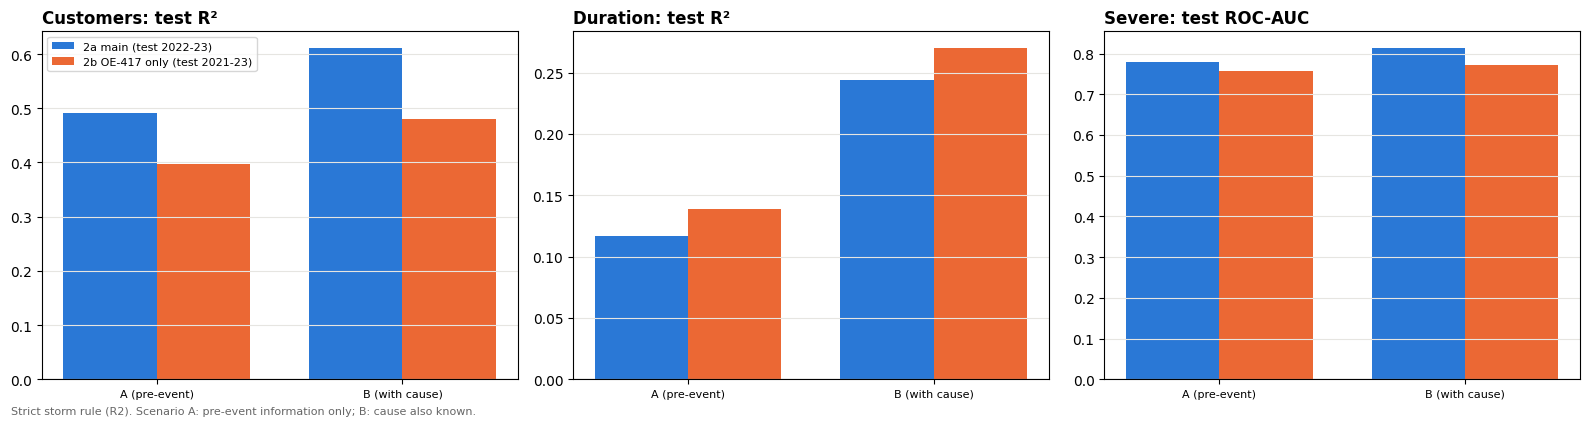

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (task, col, title) in zip(axes, [("customers_reg", "test_R2", "Customers: test R²"), ("duration_reg", "test_R2", "Duration: test R²"),
                                          ("is_severe", "test_ROC_AUC", "Severe: test ROC-AUC")]):
    b = best[best["task"] == task]
    labels = ["A (pre-event)" if s[0] == "A" else "B (with cause)" for r in RULES for s in SCENARIO_LIST]
    x = np.arange(len(labels)); wdt = 0.38
    for k, (setup, colr) in enumerate([("2a_main", "#2a78d6"), ("2b_oe417_only", "#eb6834")]):
        vals = [b[(b["setup"] == setup) & (b["rule"] == r) & (b["scenario"] == s)][col].mean() for r in RULES for s in SCENARIO_LIST]
        ax.bar(x + (k - 0.5) * wdt, vals, wdt, color=colr, label={"2a_main": "2a main (test 2022-23)", "2b_oe417_only": "2b OE-417 only (test 2021-23)"}[setup])
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8); ax.set_title(title, loc="left", fontweight="bold")
    ax.axhline(0, color="#8a8984", lw=0.8); ax.grid(axis="y", color="#e6e5e1")
axes[0].legend(fontsize=8)
fig.text(0.01, 0.0, "Strict storm rule (R2). Scenario A: pre-event information only; B: cause also known.", fontsize=8, color="#666")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "exp2_selected_models.png"), dpi=150); plt.show()

### 9.5 Setup 2a vs 2b (selected models)

In [31]:
key = ["rule", "scenario", "task"]
a = best[best["setup"] == "2a_main"].set_index(key); b = best[best["setup"] == "2b_oe417_only"].set_index(key)
cmp = pd.DataFrame({"2a test R² / ROC-AUC": np.where(a.index.get_level_values("task") == "is_severe", a["test_ROC_AUC"], a["test_R2"]),
                    "2b test R² / ROC-AUC": np.where(b.reindex(a.index).index.get_level_values("task") == "is_severe",
                                                     b.reindex(a.index)["test_ROC_AUC"], b.reindex(a.index)["test_R2"]),
                    "2a model": a["model"], "2b model": b.reindex(a.index)["model"]}, index=a.index)
cmp.to_csv(os.path.join(OUT_DIR, "exp2_setup_comparison.csv"))
display(cmp.round(3))

2a test R² / ROC-AUC  2b test R² / ROC-AUC      2a model      2b model
rule      scenario     task                                                                                 
R2_strict A_pre_event  customers_reg                 0.490                 0.398  RandomForest  RandomForest
                       duration_reg                  0.117                 0.139  RandomForest         Ridge
                       is_severe                     0.780                 0.758      Logistic       XGBoost
          B_with_cause customers_reg                 0.611                 0.481         Lasso         Lasso
                       duration_reg                  0.244                 0.270         Lasso  RandomForest
                       is_severe                     0.814                 0.771      Logistic  RandomForest

## 10. Notes for interpretation

- The selected model is chosen by cross-validation on the training years, never by the test score.
- Test periods are short (2 or 3 years), so differences of a few hundredths are within the noise shown in Experiment 1.
- Scenario B uses the reported cause, which is known only after the event; it is an upper reference, not an operational setting.
- PR-AUC depends on the share of severe outages in the test period (`test_base_rate`); ROC-AUC does not.